Plenty of great torch_tensorrt example notebooks reside [here](https://github.com/pytorch/TensorRT/tree/master/notebooks).  This notebook was adapted from the efn notebook in that folder.

In [1]:
!pip install --upgrade --index-url https://pypi.ngc.nvidia.com nvidia-tensorrt

Looking in indexes: https://pypi.ngc.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 340.9/340.9 MB 3.4 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.1/333.1 MB 3.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 42.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.3/719.3 MB 1.7 MB/s eta 0:00:0000:0100:01
  Created wheel for nvidia-cublas-cu11: filename=nvidia_cublas_cu11-2022.4.8-py3-none-any.whl size=15624 sha256=e96175d6cfaaa21cc34642a4fc009331093510fb2c24645a17be7f93bdeccdfc
  Stored in directory: /root/.cache/pip/wheels/e2/c3/94/1ffd5bac267cfdc2b222a4ec6915278ef18a028a916b9a5ac3
  Created wheel for nvidia-cuda-runtime-cu11: filename=nvidia_cuda_runtime_cu11-2022.4.25-py3-none-any.whl size=15696 sha256=ff7ccb9f222676c383a19dc854e48c74d793b765fe62102167543187f8fc5aa9
 

In [2]:
import tensorrt
print(tensorrt.__version__)
assert tensorrt.Builder(tensorrt.Logger())

8.4.3.1


In [3]:
!sudo apt-get install -y tensorrt

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following additional packages will be installed:
  libnvinfer-bin libnvinfer-dev libnvinfer-plugin-dev libnvinfer-plugin8
  libnvinfer-samples libnvinfer8 libnvonnxparsers-dev libnvonnxparsers8
  libnvparsers-dev libnvparsers8 python3-libnvinfer
The following NEW packages will be installed:
  libnvinfer-bin libnvinfer-dev libnvinfer-plugin-dev libnvinfer-samples
  libnvonnxparsers-dev libnvparsers-dev tensorrt
The following packages will be upgraded:
  libnvinfer-plugin8 libnvinfer8 libnvonnxparsers8 libnvparsers8
  python3-libnvinfer
5 upgraded, 7 newly installed, 0 to remove and 88 not upgraded.
Need to get 824 MB of archives.
After this operation, 1302 MB of additional disk space will be used.
Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  python3-libnvinfer 8.4.3-1+cuda11.6 [575 kB]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubun

In [4]:
#upgrade pytorch to 1.12
!pip install /kaggle/input/pytorch112-cu113/{torch-1.12.1+cu113-cp37-cp37m-linux_x86_64.whl,torchvision-0.13.1+cu113-cp37-cp37m-linux_x86_64.whl}
#install nvidia-pyindex
!pip install /kaggle/input/torch-tensorrt-pkg/nvidia_pyindex-1.0.9-py3-none-any.whl
#install nvidia_tensorrt
!mkdir -p /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cublas-cu11-2022.4.8.xyz /tmp/pip/cache/nvidia-cublas-cu11-2022.4.8.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cuda-runtime-cu11-2022.4.25.xyz /tmp/pip/cache/nvidia-cuda-runtime-cu11-2022.4.25.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cudnn-cu11-2022.5.19.xyz /tmp/pip/cache/nvidia-cudnn-cu11-2022.5.19.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cublas_cu117-11.10.1.25-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cuda_runtime_cu117-11.7.60-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cudnn_cu116-8.4.0.27-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_tensorrt-8.4.3.1-cp37-none-linux_x86_64.whl /tmp/pip/cache/
!pip install --no-index --find-links /tmp/pip/cache/ nvidia_tensorrt
#install torch_tensorrt
!pip install /kaggle/input/torch-tensorrt-pkg/torch_tensorrt-1.2.0-cp37-cp37m-linux_x86_64.whl

Processing /kaggle/input/pytorch112-cu113/torch-1.12.1+cu113-cp37-cp37m-linux_x86_64.whl
Processing /kaggle/input/pytorch112-cu113/torchvision-0.13.1+cu113-cp37-cp37m-linux_x86_64.whl
  Attempting uninstall: torch
    Found existing installation: torch 1.11.0
    Uninstalling torch-1.11.0:
      Successfully uninstalled torch-1.11.0
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.12.0
    Uninstalling torchvision-0.12.0:
      Successfully uninstalled torchvision-0.12.0
Processing /kaggle/input/torch-tensorrt-pkg/nvidia_pyindex-1.0.9-py3-none-any.whl
Looking in links: /tmp/pip/cache/
Processing /kaggle/input/torch-tensorrt-pkg/torch_tensorrt-1.2.0-cp37-cp37m-linux_x86_64.whl


In [5]:
!sudo apt-get install python3-libnvinfer-dev -y
!python3 -m pip install numpy onnx
!sudo apt-get install onnx-graphsurgeon -y
#--------------------------------------------------
#upgrade pytorch to 1.12
#!pip install torch==1.12.1+cu116 torchvision==0.13.1+cu116 torchaudio==0.12.1 --extra-index-url https://download.pytorch.org/whl/cu116

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  python3-libnvinfer-dev
0 upgraded, 1 newly installed, 0 to remove and 88 not upgraded.
Need to get 3652 B of archives.
After this operation, 10.2 kB of additional disk space will be used.
Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  python3-libnvinfer-dev 8.4.3-1+cuda11.6 [3652 B]
Fetched 3652 B in 0s (25.6 kB/s)                 
Selecting previously unselected package python3-libnvinfer-dev.
(Reading database ... 109282 files and directories currently installed.)
Preparing to unpack .../python3-libnvinfer-dev_8.4.3-1+cuda11.6_amd64.deb ...
Unpacking python3-libnvinfer-dev (8.4.3-1+cuda11.6) ...
Setting up python3-libnvinfer-dev (8.4.3-1+cuda11.6) ...
Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  onnx-graphsurge

In [ ]:
!dpkg-query -W tensorrt
!dpkg -l | grep nvinfer

In [6]:
!pip install --upgrade pip
!pip install --upgrade sphinx-glpi-theme
!pip install --no-cache-dir --index-url https://pypi.nvidia.com pytorch-quantization
!pip install wget
!pip3 install -U pip && pip3 install onnxsim
!pip install onnxruntime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 9.0 MB/s eta 0:00:00:00:010:01
  Attempting uninstall: pip
    Found existing installation: pip 22.1.2
    Uninstalling pip-22.1.2:
      Successfully uninstalled pip-22.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 13.9 MB/s eta 0:00:0000:0100:01
DEPRECATION: pytorch-lightning 1.7.7 has a non-standard dependency specifier torch>=1.9.*. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of pytorch-lightning or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
DEPRECATION: torch-tensorrt 1.2.0 has a non-standard dependency specifier torch<1.13.0,>=1.12.0+cu116. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of torch-tensorrt or contact the author to suggest that they release a version with a conformin

# Import libraries and benchmarking functions

In [7]:
import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as transforms
from torchvision import models, datasets
from torch.utils.tensorboard import SummaryWriter
import onnxruntime
import onnxsim
import torch_tensorrt

import pytorch_quantization
from pytorch_quantization import nn as quant_nn
from pytorch_quantization import quant_modules
from pytorch_quantization import calib
from pytorch_quantization.tensor_quant import QuantDescriptor
from pytorch_quantization.nn.modules.tensor_quantizer import TensorQuantizer
from pytorch_quantization.nn.modules import quant_pooling
from tqdm import tqdm

print(pytorch_quantization.__version__)
print(torch_tensorrt.__version__)
print(torch.__version__)
print(torchvision.__version__)
#print(torchaudio.__version__)

import os
import sys
import warnings
import time
import numpy as np
import wget
import tarfile
import shutil
warnings.simplefilter('ignore')
import collections

from absl import logging
logging.set_verbosity(logging.FATAL)  # Disable logging as they are too noisy in notebook

import json


!mkdir -p /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b0_ra-3dd342df.pth /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b2_ra-bcdf34b7.pth /root/.cache/torch/hub/checkpoints/

# loading labels
with open("/kaggle/input/few-imagenet-examples/data/imagenet_class_index.json") as json_file: 
    d = json.load(json_file)


2.1.3
1.2.0
1.12.1+cu113
0.13.1+cu113


In [8]:
!tar xzvf /kaggle/input/imagenette/imagenette2-320.tgz

imagenette2-320/
imagenette2-320/train/
imagenette2-320/noisy_imagenette.csv
imagenette2-320/val/
imagenette2-320/val/n03394916/
imagenette2-320/val/n03417042/
imagenette2-320/val/n03445777/
imagenette2-320/val/n02102040/
imagenette2-320/val/n03425413/
imagenette2-320/val/n03888257/
imagenette2-320/val/n03028079/
imagenette2-320/val/n03000684/
imagenette2-320/val/n01440764/
imagenette2-320/val/n02979186/
imagenette2-320/val/n02979186/n02979186_7492.JPEG
imagenette2-320/val/n02979186/n02979186_491.JPEG
imagenette2-320/val/n02979186/n02979186_24591.JPEG
imagenette2-320/val/n02979186/n02979186_26451.JPEG
imagenette2-320/val/n02979186/n02979186_11372.JPEG
imagenette2-320/val/n02979186/n02979186_1792.JPEG
imagenette2-320/val/n02979186/n02979186_22111.JPEG
imagenette2-320/val/n02979186/n02979186_18450.JPEG
imagenette2-320/val/n02979186/n02979186_2002.JPEG
imagenette2-320/val/n02979186/n02979186_21910.JPEG
imagenette2-320/val/n02979186/n02979186_9232.JPEG
imagenette2-320/val/n02979186/n029791

In [9]:
# Define main data directory
DATA_DIR = '/kaggle/working/imagenette2-320' 
# Define training and validation data paths
TRAIN_DIR = os.path.join(DATA_DIR, 'train') 
VAL_DIR = os.path.join(DATA_DIR, 'val')


In [10]:
#Performing Transformations on the dataset and defining training and validation dataloaders
transform = transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            ])
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=transform)
#calib_dataset = torch.utils.data.random_split(val_dataset, [2901, 1024])[1]

train_dataloader = data.DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True,pin_memory=True,num_workers=4)
val_dataloader = data.DataLoader(val_dataset, batch_size=32, shuffle=False, drop_last=True,pin_memory=True,num_workers=4)
#calib_dataloader = data.DataLoader(calib_dataset, batch_size=64, shuffle=False, drop_last=True,pin_memory=True,num_workers=4)


In [ ]:
# Visualising an image from the validation set
import matplotlib.pyplot as plt
for images, labels in val_dataloader:
    print(labels[0])
    image = images[0]
    img = image.swapaxes(0, 1)
    img = img.swapaxes(1, 2)
    plt.imshow(img)
    break

In [11]:
#This function allows you to set the all the parameters to not have gradients, 
#allowing you to freeze the model and not undergo training during the train step. 
def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

feature_extract = True #This varaible can be set False if you want to finetune the model by updating all the parameters. 
#--------Load Torchvision Model------------------
model = models.mobilenet_v2(pretrained=True)
#model = models.resnet50(pretrained=True)
set_parameter_requires_grad(model, feature_extract)
#Define a classification head for 10 classes.
#-----Mobilenetv2---------------------------
model.classifier[1] = nn.Linear(1280, 10)
#-----Resnet50------------------------------
# num_ftrs = model.fc.in_features
# model.fc = nn.Linear(num_ftrs, 10)
#-------------------------------------------
model = model.cuda()

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

In [12]:
# Declare Learning rate
lr = 0.0001

# Use cross entropy loss for classification and SGD optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [13]:
# Define functions for training, evalution, saving checkpoint and train parameter setting function
def train(model, dataloader, crit, opt, epoch):
    model.train()
    running_loss = 0.0
    for batch, (data, labels) in enumerate(dataloader):
        data, labels = data.cuda(), labels.cuda(non_blocking=True)
        opt.zero_grad()
        out = model(data)
        loss = crit(out, labels)
        loss.backward()
        opt.step()
        running_loss += loss.item()
        if batch % 100 == 99:
            print("Batch: [%5d | %5d] loss: %.3f" % (batch + 1, len(dataloader), running_loss / 100))
            running_loss = 0.0
#         train_loss = running_loss / len(train_loader.dataset)
#         train_acc = running_corrects.double() / len(train_loader.dataset)
# def evaluate(model, dataloader, crit, epoch):
#     total = 0
#     correct = 0
#     loss = 0.0
#     class_probs = []
#     class_preds = []
#     model.eval()
#     with torch.no_grad():
#         for data, labels in dataloader:
#             data, labels = data.cuda(), labels.cuda(non_blocking=True)
#             out = model(data)
#             loss += crit(out, labels)
#             preds = torch.max(out, 1)[1]
#             class_preds.append(preds)
#             total += labels.size(0)
#             correct += (preds == labels).sum().item()
#     return correct / total

def evaluate(model, dataloader, crit, epoch, dtype='fp32'):
    total = 0
    correct = 0
    loss = 0.0
    class_probs = []
    class_preds = []

    model.eval()
    with torch.no_grad():
        for data, labels in dataloader:
            if dtype=='fp16':
                data, labels = data.cuda().half(), labels.cuda(non_blocking=True)
            else:
                data, labels = data.cuda(), labels.cuda(non_blocking=True)
            out = model(data)
            loss += crit(out, labels)
            preds = torch.max(out, 1)[1]
            class_probs.append([F.softmax(i, dim=0) for i in out])
            class_preds.append(preds)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    evaluate_probs = torch.cat([torch.stack(batch) for batch in class_probs])
    evaluate_preds = torch.cat(class_preds)

    return loss / total, correct / total

def save_checkpoint(state, ckpt_path="checkpoint.pth"):
    torch.save(state, ckpt_path)
    print("Checkpoint saved")
    
# Helper function to benchmark the model
cudnn.benchmark = True
def benchmark(model, input_shape=(1024, 1, 32, 32), dtype='fp32', nwarmup=50, nruns=1000):
    input_data = torch.randn(input_shape)
    input_data = input_data.to("cuda")
    if dtype=='fp16':
        input_data = input_data.half()
        
    print("Warm up ...")
    with torch.no_grad():
        for _ in range(nwarmup):
            features = model(input_data)
    torch.cuda.synchronize()
    
    print("Start timing ...")
    timings = []
    with torch.no_grad():
        for i in range(1, nruns+1):
            start_time = time.time()
            output = model(input_data)
            torch.cuda.synchronize()
            end_time = time.time()
            timings.append(end_time - start_time)
#             if i%10==0:
#                 print('Iteration %d/%d, avg batch time %.2f ms'%(i, nruns, np.mean(timings)*1000))

    print("Input shape:", input_data.size())
    print("Output features size:", features.size())
    print('Average batch time: %.2f ms'%(np.mean(timings)*1000))
    print('Average throughput: %.2f images/second'%(input_shape[0]/np.mean(timings)))


In [14]:
# Train the model for 5 epochs to attain an acceptable accuracy.
num_epochs=5
for epoch in range(num_epochs):
    print('Epoch: [%5d / %5d] LR: %f' % (epoch + 1, num_epochs, lr))

    train(model, train_dataloader, criterion, optimizer, epoch)
    #test_acc = evaluate(model, val_dataloader, criterion, epoch)
    test_loss, test_acc = evaluate(model, val_dataloader, criterion, epoch)

    print("Test Acc: {:.2f}%".format(100 * test_acc))
    
    
save_checkpoint({'epoch': epoch + 1,
                 'model_state_dict': model.state_dict(),
                 'acc': test_acc,
                 'opt_state_dict': optimizer.state_dict()
                 },
                ckpt_path="/kaggle/working/mobilenetv2_base_ckpt")
                #ckpt_path="/kaggle/working/resnet50_base_ckpt")

Epoch: [    1 /     5] LR: 0.000100
Batch: [  100 |   295] loss: 2.341
Batch: [  200 |   295] loss: 2.261
Test Acc: 31.84%
Epoch: [    2 /     5] LR: 0.000100
Batch: [  100 |   295] loss: 2.082
Batch: [  200 |   295] loss: 2.015
Test Acc: 60.17%
Epoch: [    3 /     5] LR: 0.000100
Batch: [  100 |   295] loss: 1.870
Batch: [  200 |   295] loss: 1.800
Test Acc: 78.43%
Epoch: [    4 /     5] LR: 0.000100
Batch: [  100 |   295] loss: 1.681
Batch: [  200 |   295] loss: 1.624
Test Acc: 86.27%
Epoch: [    5 /     5] LR: 0.000100
Batch: [  100 |   295] loss: 1.505
Batch: [  200 |   295] loss: 1.471
Test Acc: 89.86%
Checkpoint saved


In [15]:
# Evaluate and benchmark the performance of the baseline Pytorch model (FP32 Model)
test_loss, test_acc = evaluate(model, val_dataloader, criterion, 0)
print("Mobilenetv2 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))
#print("Resnet50 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))

benchmark(model, input_shape=(64, 3, 224, 224))

Mobilenetv2 TRT Baseline accuracy: 89.86%
Warm up ...
Start timing ...
Input shape: torch.Size([64, 3, 224, 224])
Output features size: torch.Size([64, 10])
Average batch time: 57.99 ms
Average throughput: 1103.60 images/second


In [ ]:
model

In [ ]:
# Global list to store the activations of the first layer
activations = []

# Hook function to capture the activations
def get_activations_hook(module, input, output):
    global activations
    activations = output.detach().cpu().numpy().flatten() # Flatten the activations

# Register the hook with the first layer
hook_handle = q_model.layer4[1].conv1.register_forward_hook(get_activations_hook)

# Create a dummy input tensor
dummy_input = torch.randn(1, 3, 224, 224).cuda()


In [ ]:
# Make a forward pass through the first layer
q_model = q_model(dummy_input).cuda()


In [ ]:

# Unregister the hook
hook_handle.remove()

# Plot histogram for activations
plt.figure(figsize=(10, 5))
plt.hist(activations, bins=100, color='green', alpha=0.7)
plt.title('Histogram of the Activations of the First Layer')
plt.xlabel('Activation Values')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


In [18]:
# Exporting to TorchScript
with torch.no_grad():
    data = iter(val_dataloader)
    images, _ = data.next()
    jit_model = torch.jit.trace(model, images.to("cuda"))
    torch.jit.save(jit_model, "mobilenetv2_base.jit.pt")
    #torch.jit.save(jit_model, "resnet50_base_trt.jit.pt")

#Loading the Torchscript model and compiling it into a TensorRT model
#baseline_model = torch.jit.load("mobilenetv2_base_trt.jit.pt").eval()
baseline_model = torch.jit.load("mobilenetv2_base.jit.pt").eval()
compile_spec = {"inputs": [torch_tensorrt.Input([32, 3, 224, 224])]
               , "enabled_precisions": torch.float,
                "workspace_size" : 1 << 32
               }
baseline_trt_model = torch_tensorrt.compile(baseline_model, **compile_spec)

In [20]:
# Evaluate and benchmark the performance of the baseline TRT model (TRT FP32 Model)
test_loss, test_acc = evaluate(baseline_trt_model, val_dataloader, criterion, 0)
#print("Mobilenetv2 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))
print("Resnet50 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))

benchmark(baseline_trt_model, input_shape=(32, 3, 224, 224))

Resnet50 TRT Baseline accuracy: 88.93%
Warm up ...
Start timing ...
Input shape: torch.Size([32, 3, 224, 224])
Output features size: torch.Size([32, 10])
Average batch time: 14.19 ms
Average throughput: 2255.73 images/second


**Half Precision FP16 Model Inference**

In [ ]:
trt_model_fp16 = torch_tensorrt.compile(baseline_model.half().eval(), inputs = [torch_tensorrt.Input(min_shape=[32, 3, 224, 224],opt_shape=[32, 3, 224, 224],max_shape=[32, 3, 224, 224],dtype=torch.half)],
    enabled_precisions = {torch.half}, # Run with FP16
    workspace_size = 1 << 32
)

# Exporting to TorchScript
with torch.no_grad():
    data = iter(val_dataloader)
    images, _ = data.next()
    jit_model = torch.jit.trace(trt_model_fp16, images.to("cuda"))
    #torch.jit.save(jit_model, "mobilenetv2_half_trt.jit.pt")
    torch.jit.save(jit_model, "resnet50_half_trt.jit.pt")
half_trt_model = torch.jit.load("resnet50_half_trt.jit.pt").eval()

In [ ]:
# Evaluate and benchmark the performance of the baseline TRT model (TRT FP16 Model)
test_loss, test_acc = evaluate(half_trt_model.half().eval(), val_dataloader, criterion, 0, dtype='fp16')
print("Resnet50 TRT HalfPrecision-FP16 accuracy: {:.2f}%".format(100 * test_acc))
benchmark(half_trt_model, input_shape=(32, 3, 224, 224), dtype='fp16',nruns=100)

**PTQ - TensorRT torch.int8**

In [34]:
 calibrator = torch_tensorrt.ptq.DataLoaderCalibrator(val_dataloader,
                                              use_cache=False,
                                              algo_type=torch_tensorrt.ptq.CalibrationAlgo.ENTROPY_CALIBRATION_2,
                                               #algo_type=torch_tensorrt.ptq.CalibrationAlgo.MINMAX_CALIBRATION,
                                              device=torch.device('cuda:0'))


trt_ptq = torch_tensorrt.compile(baseline_model, inputs = [torch_tensorrt.Input(min_shape=[1, 3, 224, 224],opt_shape=[32, 3, 224, 224],max_shape=[128, 3, 224, 224],dtype=torch.float)],
    enabled_precisions = {torch.int8}, # Run with INT8
    calibrator=calibrator,
    truncate_long_and_double= True ,                                                      
    workspace_size = 1 << 32,
                                 
)

In [35]:
# Exporting to TorchScript
with torch.no_grad():
    data = iter(val_dataloader)
    images, _ = data.next()
    jit_model = torch.jit.trace(trt_ptq, images.to("cuda"))
    torch.jit.save(jit_model, "mobilenetv2_ptq.jit.pt")
    #torch.jit.save(jit_model, "resnet50_ptq_trt.jit.pt")
ptq_trt_model = torch.jit.load("mobilenetv2_ptq.jit.pt").eval()

In [36]:
# Evaluate the PTQ model
test_loss, test_acc = evaluate(ptq_trt_model, val_dataloader, criterion, 0)
print("Mobilenetv2 PTQ accuracy: {:.2f}%".format(100 * test_acc))
#print("Resnet50 PTQ accuracy: {:.2f}%".format(100 * test_acc))

benchmark(ptq_trt_model, input_shape=(32, 3, 224, 224))


Mobilenetv2 PTQ accuracy: 87.22%
Warm up ...
Start timing ...
Input shape: torch.Size([32, 3, 224, 224])
Output features size: torch.Size([32, 10])
Average batch time: 3.10 ms
Average throughput: 10314.08 images/second


In [ ]:
import torch
from torch import Tensor
import torch.nn as nn
from torch.hub import load_state_dict_from_url
from typing import Type, Any, Callable, Union, List, Optional
from pytorch_quantization import quant_modules
from pytorch_quantization import nn as quant_nn

__all__ = [
    'ResNet', 'resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152', 'resnext50_32x4d', 'resnext101_32x8d',
    'wide_resnet50_2', 'wide_resnet101_2'
]

model_urls = {
    'resnet18': 'https://download.pytorch.org/models/resnet18-f37072fd.pth',
    'resnet34': 'https://download.pytorch.org/models/resnet34-b627a593.pth',
    'resnet50': 'https://download.pytorch.org/models/resnet50-0676ba61.pth',
    'resnet101': 'https://download.pytorch.org/models/resnet101-63fe2227.pth',
    'resnet152': 'https://download.pytorch.org/models/resnet152-394f9c45.pth',
    'resnext50_32x4d': 'https://download.pytorch.org/models/resnext50_32x4d-7cdf4587.pth',
    'resnext101_32x8d': 'https://download.pytorch.org/models/resnext101_32x8d-8ba56ff5.pth',
    'wide_resnet50_2': 'https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth',
    'wide_resnet101_2': 'https://download.pytorch.org/models/wide_resnet101_2-32ee1156.pth',
}


def conv3x3(in_planes: int,
            out_planes: int,
            stride: int = 1,
            groups: int = 1,
            dilation: int = 1,
            quantize: bool = False) -> nn.Conv2d:
    """3x3 convolution with padding"""
    if quantize:
        return quant_nn.QuantConv2d(in_planes,
                                    out_planes,
                                    kernel_size=3,
                                    stride=stride,
                                    padding=dilation,
                                    groups=groups,
                                    bias=False,
                                    dilation=dilation)
    else:
        return nn.Conv2d(in_planes,
                         out_planes,
                         kernel_size=3,
                         stride=stride,
                         padding=dilation,
                         groups=groups,
                         bias=False,
                         dilation=dilation)


def conv1x1(in_planes: int, out_planes: int, stride: int = 1, quantize: bool = False) -> nn.Conv2d:
    """1x1 convolution"""
    if quantize:
        return quant_nn.QuantConv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)
    else:
        return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class BasicBlock(nn.Module):
    expansion: int = 1

    def __init__(self,
                 inplanes: int,
                 planes: int,
                 stride: int = 1,
                 downsample: Optional[nn.Module] = None,
                 groups: int = 1,
                 base_width: int = 64,
                 dilation: int = 1,
                 norm_layer: Optional[Callable[..., nn.Module]] = None,
                 quantize: bool = False) -> None:
        super(BasicBlock, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError('BasicBlock only supports groups=1 and base_width=64')
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride, quantize=quantize)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes, quantize=quantize)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample
        self.stride = stride
        self._quantize = quantize
        if self._quantize:
            self.residual_quantizer = quant_nn.TensorQuantizer(quant_nn.QuantConv2d.default_quant_desc_input)

    def forward(self, x: Tensor) -> Tensor:
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        if self._quantize:
            out += self.residual_quantizer(identity)
        else:
            out += identity
        out = self.relu(out)

        return out


class Bottleneck(nn.Module):
    # Bottleneck in torchvision places the stride for downsampling at 3x3 convolution(self.conv2)
    # while original implementation places the stride at the first 1x1 convolution(self.conv1)
    # according to "Deep residual learning for image recognition"https://arxiv.org/abs/1512.03385.
    # This variant is also known as ResNet V1.5 and improves accuracy according to
    # https://ngc.nvidia.com/catalog/model-scripts/nvidia:resnet_50_v1_5_for_pytorch.

    expansion: int = 4

    def __init__(self,
                 inplanes: int,
                 planes: int,
                 stride: int = 1,
                 downsample: Optional[nn.Module] = None,
                 groups: int = 1,
                 base_width: int = 64,
                 dilation: int = 1,
                 norm_layer: Optional[Callable[..., nn.Module]] = None,
                 quantize: bool = False) -> None:
        super(Bottleneck, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        width = int(planes * (base_width / 64.)) * groups
        # Both self.conv2 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv1x1(inplanes, width, quantize=quantize)
        self.bn1 = norm_layer(width)
        self.conv2 = conv3x3(width, width, stride, groups, dilation, quantize=quantize)
        self.bn2 = norm_layer(width)
        self.conv3 = conv1x1(width, planes * self.expansion, quantize=quantize)
        self.bn3 = norm_layer(planes * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride
        self._quantize = quantize
        if self._quantize:
            self.residual_quantizer = quant_nn.TensorQuantizer(quant_nn.QuantConv2d.default_quant_desc_input)

    def forward(self, x: Tensor) -> Tensor:
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        if self._quantize:
            out += self.residual_quantizer(identity)
        else:
            out += identity
        out = self.relu(out)

        return out


class ResNet(nn.Module):

    def __init__(self,
                 block: Type[Union[BasicBlock, Bottleneck]],
                 layers: List[int],
                 quantize: bool = False,
                 num_classes: int = 1000,
                 zero_init_residual: bool = False,
                 groups: int = 1,
                 width_per_group: int = 64,
                 replace_stride_with_dilation: Optional[List[bool]] = None,
                 norm_layer: Optional[Callable[..., nn.Module]] = None) -> None:
        super(ResNet, self).__init__()
        self._quantize = quantize

        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError("replace_stride_with_dilation should be None "
                             "or a 3-element tuple, got {}".format(replace_stride_with_dilation))
        self.groups = groups
        self.base_width = width_per_group

        if quantize:
            self.conv1 = quant_nn.QuantConv2d(3,
                                        self.inplanes,
                                        kernel_size=7,
                                        stride=2,
                                        padding=3,
                                        bias=False)
        else:
            self.conv1 = nn.Conv2d(3, self.inplanes, kernel_size=7, stride=2, padding=3, bias=False)

        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        if quantize:
            self.maxpool = quant_nn.QuantMaxPool2d(kernel_size=3, stride=2, padding=1)
        else:
            self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0], quantize=quantize)
        self.layer2 = self._make_layer(block,
                                       128,
                                       layers[1],
                                       stride=2,
                                       dilate=replace_stride_with_dilation[0],
                                       quantize=quantize)
        self.layer3 = self._make_layer(block,
                                       256,
                                       layers[2],
                                       stride=2,
                                       dilate=replace_stride_with_dilation[1],
                                       quantize=quantize)
        self.layer4 = self._make_layer(block,
                                       512,
                                       layers[3],
                                       stride=2,
                                       dilate=replace_stride_with_dilation[2],
                                       quantize=quantize)
        if quantize:
            self.avgpool = quant_nn.QuantAdaptiveAvgPool2d((1, 1))
        else:
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        if quantize:
            self.fc = quant_nn.QuantLinear(512 * block.expansion, num_classes)
        else:
            self.fc = nn.Linear(512 * block.expansion, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, Bottleneck):
                    nn.init.constant_(m.bn3.weight, 0)  # type: ignore[arg-type]
                elif isinstance(m, BasicBlock):
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(self,
                    block: Type[Union[BasicBlock, Bottleneck]],
                    planes: int,
                    blocks: int,
                    stride: int = 1,
                    dilate: bool = False,
                    quantize: bool = False) -> nn.Sequential:
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride, quantize=quantize),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(
            block(self.inplanes, planes, stride, downsample, self.groups, self.base_width, previous_dilation,
                  norm_layer, self._quantize))
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(self.inplanes,
                      planes,
                      groups=self.groups,
                      base_width=self.base_width,
                      dilation=self.dilation,
                      norm_layer=norm_layer,
                      quantize=quantize))

        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        # See note [TorchScript super()]
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)


def _resnet(arch: str, block: Type[Union[BasicBlock, Bottleneck]], layers: List[int], pretrained: bool, progress: bool,
            quantize: bool, **kwargs: Any) -> ResNet:
    model = ResNet(block, layers, quantize, **kwargs)
    if pretrained:
        state_dict = load_state_dict_from_url(model_urls[arch], progress=progress)
        model.load_state_dict(state_dict)
    return model


def resnet18(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNet-18 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet18', BasicBlock, [2, 2, 2, 2], pretrained, progress, quantize, **kwargs)


def resnet34(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNet-34 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet34', BasicBlock, [3, 4, 6, 3], pretrained, progress, quantize, **kwargs)


def resnet50(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNet-50 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet50', Bottleneck, [3, 4, 6, 3], pretrained, progress, quantize, **kwargs)


def resnet101(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNet-101 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet101', Bottleneck, [3, 4, 23, 3], pretrained, progress, quantize, **kwargs)


def resnet152(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNet-152 model from
    `"Deep Residual Learning for Image Recognition" <https://arxiv.org/pdf/1512.03385.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet152', Bottleneck, [3, 8, 36, 3], pretrained, progress, quantize, **kwargs)


def resnext50_32x4d(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNeXt-50 32x4d model from
    `"Aggregated Residual Transformation for Deep Neural Networks" <https://arxiv.org/pdf/1611.05431.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['groups'] = 32
    kwargs['width_per_group'] = 4
    return _resnet('resnext50_32x4d', Bottleneck, [3, 4, 6, 3], pretrained, progress, quantize, **kwargs)


def resnext101_32x8d(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""ResNeXt-101 32x8d model from
    `"Aggregated Residual Transformation for Deep Neural Networks" <https://arxiv.org/pdf/1611.05431.pdf>`_.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['groups'] = 32
    kwargs['width_per_group'] = 8
    return _resnet('resnext101_32x8d', Bottleneck, [3, 4, 23, 3], pretrained, progress, quantize, **kwargs)


def wide_resnet50_2(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""Wide ResNet-50-2 model from
    `"Wide Residual Networks" <https://arxiv.org/pdf/1605.07146.pdf>`_.

    The model is the same as ResNet except for the bottleneck number of channels
    which is twice larger in every block. The number of channels in outer 1x1
    convolutions is the same, e.g. last block in ResNet-50 has 2048-512-2048
    channels, and in Wide ResNet-50-2 has 2048-1024-2048.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['width_per_group'] = 64 * 2
    return _resnet('wide_resnet50_2', Bottleneck, [3, 4, 6, 3], pretrained, progress, quantize, **kwargs)


def wide_resnet101_2(pretrained: bool = False, progress: bool = True, quantize: bool = False, **kwargs: Any) -> ResNet:
    r"""Wide ResNet-101-2 model from
    `"Wide Residual Networks" <https://arxiv.org/pdf/1605.07146.pdf>`_.

    The model is the same as ResNet except for the bottleneck number of channels
    which is twice larger in every block. The number of channels in outer 1x1
    convolutions is the same, e.g. last block in ResNet-50 has 2048-512-2048
    channels, and in Wide ResNet-50-2 has 2048-1024-2048.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['width_per_group'] = 64 * 2
    return _resnet('wide_resnet101_2', Bottleneck, [3, 4, 23, 3], pretrained, progress, quantize, **kwargs)


**Pytorch-Quantization Nvidia TensorRT QAT (INT8)**

In [27]:
#-----------per channel weight-----------------------------------
quant_desc_input = QuantDescriptor(num_bits=8, calib_method='histogram')
quant_nn.QuantConv2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantMaxPool2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantAdaptiveAvgPool2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantLinear.set_default_quant_desc_input(quant_desc_input)

# #-----------per tensor weight--------------------------------------
# quant_desc_input = QuantDescriptor(num_bits=4, calib_method='histogram', axis=None)
# quant_nn.QuantConv2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantMaxPool2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantConvTranspose2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantLinear.set_default_quant_desc_input(quant_desc_input)

# quant_desc_weight = QuantDescriptor(num_bits=4, calib_method='histogram', axis=None)
# quant_nn.QuantConv2d.set_default_quant_desc_weight(quant_desc_weight)
# quant_nn.QuantConvTranspose2d.set_default_quant_desc_weight(quant_desc_weight)
# quant_nn.QuantLinear.set_default_quant_desc_weight(quant_desc_weight)


In [16]:
quant_modules.initialize()


In [28]:
# We define Mobilenetv2 again just like we did above
# All the regular conv, FC layers will be converted to their quantized counterparts due to quant_modules.initialize()
feature_extract = True
q_model = models.mobilenet_v2(pretrained=True)
#q_model =  models.resnet50(pretrained=True)
#q_model = models.resnet50(pretrained=True)
set_parameter_requires_grad(q_model, feature_extract)
#----Resnet50 Model-------------------
# num_ftrs = q_model.fc.in_features
# q_model.fc = nn.Linear(num_ftrs, 10)
#----Mobilenetv2 Model-------------------
q_model.classifier[1] = nn.Linear(1280, 10)
#------------------------------------------
q_model = q_model.cuda()

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): QuantConv2d(
        3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False
        (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=dynamic calibrator=HistogramCalibrator scale=1.0 quant)
        (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=dynamic calibrator=MaxCalibrator scale=1.0 quant)
      )
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): QuantConv2d(
            32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False
            (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=dynamic calibrator=HistogramCalibrator scale=1.0 quant)
            (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=dynamic calibrator=MaxCalibrator scale=1

In [30]:
# mobilenetv2_base_ckpt is the checkpoint generated from Step 2 : Training a baseline Mobilenetv2 model.
ckpt = torch.load("/kaggle/working/mobilenetv2_base_ckpt")
#ckpt = torch.load("/kaggle/working/resnet50_base_ckpt")
modified_state_dict={}
for key, val in ckpt["model_state_dict"].items():
    # Remove 'module.' from the key names
    if key.startswith('module'):
        modified_state_dict[key[7:]] = val
    else:
        modified_state_dict[key] = val

# Load the pre-trained checkpoint
q_model.load_state_dict(modified_state_dict)
optimizer.load_state_dict(ckpt["opt_state_dict"])

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): QuantConv2d(
        3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False
        (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=1.0000 calibrator=MaxCalibrator scale=1.0 quant)
        (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0039, 1.4805](32) calibrator=MaxCalibrator scale=1.0 quant)
      )
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): QuantConv2d(
            32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False
            (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=6.0000 calibrator=MaxCalibrator scale=1.0 quant)
            (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0036, 2.6916](32) calibrator=MaxCalibr

In [31]:
def compute_amax(model, **kwargs):
    # Load calib result
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                if isinstance(module._calibrator, calib.MaxCalibrator):
                    module.load_calib_amax()
                else:
                    module.load_calib_amax(**kwargs)
            print(F"{name:40}: {module}")
    model.cuda()

def collect_stats(model, data_loader, num_batches):
    """Feed data to the network and collect statistics"""
    # Enable calibrators
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                module.disable_quant()
                module.enable_calib()
            else:
                module.disable()

    # Feed data to the network for collecting stats
    for i, (image, _) in tqdm(enumerate(data_loader), total=num_batches):
        model(image.cuda())
        if i >= num_batches:
            break

    # Disable calibrators
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                module.enable_quant()
                module.disable_calib()
            else:
                module.enable()

def calibrate_model(model, model_name, data_loader, num_calib_batch, calibrator, hist_percentile, out_dir):
    """
        Feed data to the network and calibrate.
        Arguments:
            model: classification model
            model_name: name to use when creating state files
            data_loader: calibration data set
            num_calib_batch: amount of calibration passes to perform
            calibrator: type of calibration to use (max/histogram)
            hist_percentile: percentiles to be used for historgram calibration
            out_dir: dir to save state files in
    """

    if num_calib_batch > 0:
        print("Calibrating model")
        with torch.no_grad():
            collect_stats(model, data_loader, num_calib_batch)

        if not calibrator == "histogram":
            compute_amax(model, method="max")
            calib_output = os.path.join(
                out_dir,
                F"{model_name}-max-{num_calib_batch*data_loader.batch_size}.pth")
            torch.save(model.state_dict(), calib_output)
        else:
            for percentile in hist_percentile:
                print(F"{percentile} percentile calibration")
                compute_amax(model, method="percentile")
                calib_output = os.path.join(
                    out_dir,
                    F"{model_name}-percentile-{percentile}-{num_calib_batch*data_loader.batch_size}.pth")
                torch.save(model.state_dict(), calib_output)

            for method in ["mse", "entropy"]:
                print(F"{method} calibration")
                compute_amax(model, method=method)
                calib_output = os.path.join(
                    out_dir,
                    F"{model_name}-{method}-{num_calib_batch*data_loader.batch_size}.pth")
                torch.save(model.state_dict(), calib_output)

In [20]:
!mkdir calib_cache

In [32]:
#Calibrate the model using max calibration technique.
with torch.no_grad():
    calibrate_model(
        model=q_model,
        model_name="mobilenet_v2",
        data_loader=train_dataloader,
        num_calib_batch=32,
        calibrator="histogram",
        hist_percentile=[99.9, 99.99], 
        out_dir="/kaggle/working/calib_cache/")
"""[ 99.99, 99.999, 99.9999]"""

Calibrating model


100%|██████████| 32/32 [00:08<00:00,  3.96it/s]


99.9 percentile calibration
features.0.0._input_quantizer           : TensorQuantizer(8bit fake per-tensor amax=0.9995 calibrator=HistogramCalibrator scale=1.0 quant)
features.0.0._weight_quantizer          : TensorQuantizer(8bit fake axis=0 amax=[0.0039, 1.4805](32) calibrator=MaxCalibrator scale=1.0 quant)
features.1.conv.0.0._input_quantizer    : TensorQuantizer(8bit fake per-tensor amax=2.8103 calibrator=HistogramCalibrator scale=1.0 quant)
features.1.conv.0.0._weight_quantizer   : TensorQuantizer(8bit fake axis=0 amax=[0.0036, 2.6916](32) calibrator=MaxCalibrator scale=1.0 quant)
features.1.conv.1._input_quantizer      : TensorQuantizer(8bit fake per-tensor amax=5.9971 calibrator=HistogramCalibrator scale=1.0 quant)
features.1.conv.1._weight_quantizer     : TensorQuantizer(8bit fake axis=0 amax=[0.4161, 1.1874](16) calibrator=MaxCalibrator scale=1.0 quant)
features.2.conv.0.0._input_quantizer    : TensorQuantizer(8bit fake per-tensor amax=4.3906 calibrator=HistogramCalibrator scal

'[ 99.99, 99.999, 99.9999]'

In [49]:
#Evaluate model upon calibration
test_loss, test_acc = evaluate(q_model_perc, val_dataloader, criterion, 0)
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))
#benchmark(q_model, input_shape=(64, 3, 224, 224))
#Evaluate model upon calibration
test_loss, test_acc = evaluate(q_model_perc_, val_dataloader, criterion, 0)
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))
#Evaluate model upon calibration
test_loss, test_acc = evaluate(q_model_mse, val_dataloader, criterion, 0)
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))

#Evaluate model upon calibration
test_loss, test_acc = evaluate(q_model_entropy, val_dataloader, criterion, 0)
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))

Resnet50 QAT accuracy using TensorRT: 87.68%
Resnet50 QAT accuracy using TensorRT: 87.68%
Resnet50 QAT accuracy using TensorRT: 87.68%
Resnet50 QAT accuracy using TensorRT: 87.68%


In [34]:
#Evaluate model upon calibration
test_loss, test_acc = evaluate(model, val_dataloader, criterion, 0)
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))

Resnet50 QAT accuracy using TensorRT: 89.86%


In [57]:
q_model_entropy

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): QuantConv2d(
        3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False
        (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=1.0000 calibrator=HistogramCalibrator scale=1.0 quant)
        (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0039, 1.4805](32) calibrator=MaxCalibrator scale=1.0 quant)
      )
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): QuantConv2d(
            32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False
            (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=2.7727 calibrator=HistogramCalibrator scale=1.0 quant)
            (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0036, 2.6916](32) calibrat

In [24]:
q_model.load_state_dict(torch.load('/kaggle/working/calib_cache/mobilenet_v2-percentile-99.9-1024.pth'))
q_model.eval()

# q_model_perc_ = q_model.load_state_dict(torch.load('/kaggle/working/calib_cache/mobilenet_v2-percentile-99.99-1024.pth'))
# q_model_perc_ = q_model.eval()

# q_model_mse = q_model.load_state_dict(torch.load('/kaggle/working/calib_cache/mobilenet_v2-mse-1024.pth'))
# q_model_mse = q_model.eval()

# q_model_entropy = q_model.load_state_dict(torch.load('/kaggle/working/calib_cache/mobilenet_v2-entropy-1024.pth'))
# q_model_entropy = q_model.eval()


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): QuantConv2d(
        3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False
        (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=1.0000 calibrator=MaxCalibrator scale=1.0 quant)
        (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0039, 1.4805](32) calibrator=MaxCalibrator scale=1.0 quant)
      )
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): QuantConv2d(
            32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False
            (_input_quantizer): TensorQuantizer(8bit fake per-tensor amax=6.0000 calibrator=MaxCalibrator scale=1.0 quant)
            (_weight_quantizer): TensorQuantizer(8bit fake axis=0 amax=[0.0036, 2.6916](32) calibrator=MaxCalibr

In [ ]:
def build_sensitivity_profile(model, criterion, data_loader_test):
    quant_layer_names = []
    # Disable quantization for all layers initially
    for name, module in model.named_modules():
        if name.endswith("_quantizer"):
            module.disable()
            # Strip the quantizer suffix to get the base layer name
            layer_name = name.replace("._input_quantizer", "").replace("._weight_quantizer", "")
            if layer_name not in quant_layer_names:
                quant_layer_names.append(layer_name)
    
    # Evaluate the impact of quantizing each layer independently
    for i, quant_layer in enumerate(quant_layer_names):
        print("Enable quantization for layer:", quant_layer)
        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.enable()  # Enable quantization for the current layer
                print(f"{name:40}: {module}")
        
        # Evaluate the model with the current layer quantized
        with torch.no_grad():
            test_loss, test_acc = evaluate(model.eval(), data_loader_test, criterion, 0)
        print(f"Loss: {test_loss}, Accuracy: {test_acc}% for layer {quant_layer}")
        
        # Disable quantization again for the layer
        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.disable()
                print(f"{name:40}: {module}")
    
    # Print out all layers that were analyzed for sensitivity
    print("Quantization sensitivity analysis completed for layers:", quant_layer_names)


Enable quantization for layer: features.0.0
Enable quantization for layer: features.1.conv.0.0
Enable quantization for layer: features.1.conv.1
Enable quantization for layer: features.2.conv.0.0
Enable quantization for layer: features.2.conv.1.0
Enable quantization for layer: features.2.conv.2
Enable quantization for layer: features.3.conv.0.0
Enable quantization for layer: features.3.conv.1.0
Enable quantization for layer: features.3.conv.2
Enable quantization for layer: features.4.conv.0.0
Enable quantization for layer: features.4.conv.1.0
Enable quantization for layer: features.4.conv.2
Enable quantization for layer: features.5.conv.0.0
Enable quantization for layer: features.5.conv.1.0
Enable quantization for layer: features.5.conv.2
Enable quantization for layer: features.6.conv.0.0
Enable quantization for layer: features.6.conv.1.0
Enable quantization for layer: features.6.conv.2
Enable quantization for layer: features.7.conv.0.0
Enable quantization for layer: features.7.conv.1.0

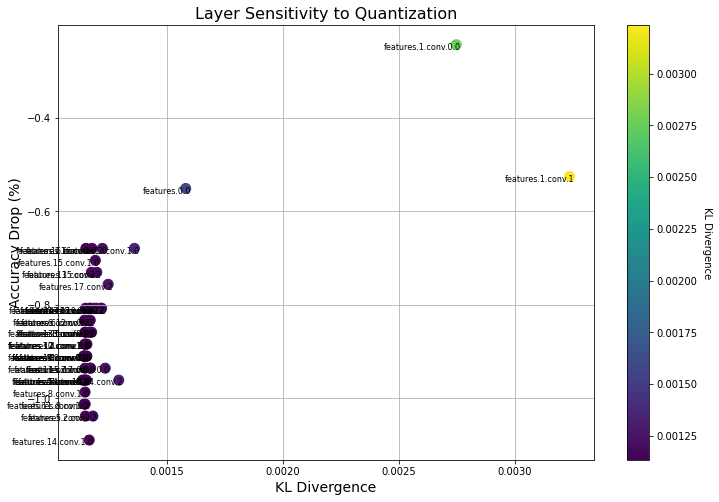

In [39]:
build_sensitivity_profile_(model, q_model, criterion, val_dataloader, '0.8928')

In [37]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def evaluate_kl_divergence(original_model, quantized_model, data_loader):
    kl_divergence = 0.0
    with torch.no_grad():
        for inputs, _ in data_loader:
            original_outputs = original_model(inputs.cuda())
            quantized_outputs = quantized_model(inputs.cuda())
            kl_divergence += torch.nn.functional.kl_div(
                original_outputs.log_softmax(dim=1),
                quantized_outputs.softmax(dim=1),
                reduction='batchmean'
            ).item()
    return kl_divergence / len(data_loader)

def build_sensitivity_profile_(baseline_model, model, criterion, data_loader_test, original_accuracy):
    original_model = baseline_model.cuda().eval()
    quant_layer_names = []
    sensitivity_info = []

    layers = []
    kl_divergences = []
    current_accuracies = []
    original_accuracy = original_accuracy

    for name, module in model.named_modules():
        if name.endswith("_quantizer"):
            module.disable()
            layer_name = name.replace("._input_quantizer", "").replace("._weight_quantizer", "")
            if layer_name not in quant_layer_names:
                quant_layer_names.append(layer_name)

    for i, quant_layer in enumerate(quant_layer_names):
        print("Enable quantization for layer:", quant_layer)
        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.enable()

        with torch.no_grad():
            kl_divergence = evaluate_kl_divergence(original_model, model, data_loader_test)
            test_loss, test_acc = evaluate(model, data_loader_test, criterion, 0)

        layers.append(quant_layer)
        kl_divergences.append(kl_divergence)
        current_accuracies.append(test_acc)

        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.disable()

    print("Quantization sensitivity analysis completed for layers:", quant_layer_names)

    # Plot the data
    plot_quantization_sensitivity(layers, kl_divergences, original_accuracy, current_accuracies)

# def plot_quantization_sensitivity(layers, kl_divergences, original_accuracy, current_accuracies):
#     accuracy_drops = [(original_accuracy - acc) * 100 for acc in current_accuracies]
    
#     plt.figure(figsize=(12, 8))
#     scatter = plt.scatter(kl_divergences, accuracy_drops, c=kl_divergences, cmap='viridis', s=100)
    
#     for i, layer in enumerate(layers):
#         plt.annotate(layer, (kl_divergences[i], accuracy_drops[i]), textcoords="offset points", xytext=(5,-5), ha='right', fontsize=8)
    
#     cbar = plt.colorbar(scatter)
#     cbar.set_label('KL Divergence', rotation=270, labelpad=15)
    
#     plt.title('Layer Sensitivity to Quantization', fontsize=16)
#     plt.xlabel('KL Divergence', fontsize=14)
#     plt.ylabel('Accuracy Drop (%)', fontsize=14)
#     plt.grid(True)
#     plt.show()

def plot_quantization_sensitivity(layers, kl_divergences, original_accuracy, current_accuracies):
    # Convert original_accuracy from string to float if it is not already a float
    original_accuracy = float(original_accuracy) if isinstance(original_accuracy, str) else original_accuracy
    accuracy_drops = [(original_accuracy - acc) * 100 for acc in current_accuracies]
    
    plt.figure(figsize=(12, 8))
    scatter = plt.scatter(kl_divergences, accuracy_drops, c=kl_divergences, cmap='viridis', s=100)
    
    for i, layer in enumerate(layers):
        plt.annotate(layer, (kl_divergences[i], accuracy_drops[i]), textcoords="offset points", xytext=(5,-5), ha='right', fontsize=8)
    
    cbar = plt.colorbar(scatter)
    cbar.set_label('KL Divergence', rotation=270, labelpad=15)
    
    plt.title('Layer Sensitivity to Quantization', fontsize=16)
    plt.xlabel('KL Divergence', fontsize=14)
    plt.ylabel('Accuracy Drop (%)', fontsize=14)
    plt.grid(True)
    plt.show()


In [58]:
def build_sensitivity_profile_l(baseline_model, model, data_loader_test, original_accuracy, bit_widths):
    original_model = baseline_model.cuda().eval()
    quant_layer_names = []
    sensitivity_info = {}
    
    for bit_width in bit_widths:
        sensitivity_info[bit_width] = []
    
    # Assuming that 'model' is already wrapped with a quantization-aware training framework
    for name, module in model.named_modules():
        if name.endswith("_quantizer"):
            # Let's extract only the layer's name without '_quantizer'
            layer_name = name.replace("._input_quantizer", "").replace("._weight_quantizer", "")
            if layer_name not in quant_layer_names:
                quant_layer_names.append(layer_name)
    
    for bit_width in bit_widths:
        print(f"Evaluating for bit width: {bit_width}")
        for quant_layer in quant_layer_names:
            # Enable quantization only for the current layer and set its bit width
            enable_quantization_for_layer(model,layer_name ,bit_width)
            
            # Evaluate the KL divergence with the layer at the current bit width
            kl_divergence = evaluate_kl_divergence(original_model, model, data_loader_test)
            
            sensitivity_info[bit_width].append(kl_divergence)
            
            # Disable quantization for the current layer after evaluation
            disable_quantization_for_layer(model, layer_name)
    
    return quant_layer_names, sensitivity_info




In [59]:
# Example: Function to enable/disable quantization and set bit-width for layers
def enable_quantization_for_layer(model, layer_name,bit_width):
    for module in model.modules():
        if isinstance(module, TensorQuantizer):
            module.enable_quant()
            module.bit_width = bit_width

def disable_quantization_for_layer(model, layer_name):
    for module in model.modules():
        if isinstance(module, TensorQuantizer):
            module.disable_quant()

In [60]:
bit_widths = [8,6,4,2]
build_sensitivity_profile_l(model, q_model, val_dataloader, 0.8928, bit_widths)

Evaluating for bit width: 8


KeyboardInterrupt: 

In [41]:
from pytorch_quantization.nn import QuantConv2d, QuantLinear

def set_bit_precision_for_layers(model, config):
    """
    Set the bit precision for layers of a quantized model.
    
    Args:
    model: The quantized PyTorch model.
    config: A list or tuple of bit precisions corresponding to each quantizable layer in the model.
    """
    # Iterate over model modules and configuration simultaneously
    config_index = 0  # Index to keep track of which bit width to apply next
    for module in model.modules():
        # Check if the module is a quantizable layer (e.g., QuantConv2d, QuantLinear)
        if isinstance(module, (QuantConv2d, QuantLinear)):
            # Check if there is a weight quantizer attribute
            if hasattr(module, '._weight_quantizer'):
                # Set the bit width for the layer's weight quantizer
                module.weight_quantizer.bit_width = config[config_index]
            
            # Similarly, check and set for activation quantizer if it exists
            if hasattr(module, '._input_quantizer'):
                # Note: Activation quantization is usually uniform across the model
                # But can be set individually if required
                module._input_quantizer.bit_width = config[config_index]
            
            # Move to the next bit configuration
            config_index += 1
            
            # Ensure we don't exceed the configuration list
            if config_index >= len(config):
                break  # Exit the loop if we've applied all configurations

                
new_config = [8, 4, 8, 2, 4]
set_bit_precision_for_layers(q_model, new_config)


In [ ]:
def build_sensitivity_profile_(baseline_model, model, data_loader_test, original_accuracy, bit_widths):
    original_model = baseline_model.cuda().eval()
    quant_layer_names = []
    sensitivity_info = {}
    
    for bit_width in bit_widths:
        sensitivity_info[bit_width] = []
    
    # Assuming that 'model' is already wrapped with a quantization-aware training framework
    for name, module in model.named_modules():
        if name.endswith("_quantizer"):
            # Let's extract only the layer's name without '_quantizer'
            layer_name = name.replace("._input_quantizer", "").replace("._weight_quantizer", "")
            if layer_name not in quant_layer_names:
                quant_layer_names.append(layer_name)
    
    for bit_width in bit_widths:
        print(f"Evaluating for bit width: {bit_width}")
        for quant_layer in quant_layer_names:
            # Enable quantization only for the current layer and set its bit width
            enable_quantization_for_layer(model, quant_layer, bit_width)
            
            # Evaluate the KL divergence with the layer at the current bit width
            kl_divergence = evaluate_kl_divergence(original_model, model, data_loader_test)
            
            sensitivity_info[bit_width].append(kl_divergence)
            
            # Disable quantization for the current layer after evaluation
            disable_quantization_for_layer(model, quant_layer)
    
    return quant_layer_names, sensitivity_info

# Helper functions to enable/disable quantization per layer and set bit-width, which you need to define
def enable_quantization_for_layer(model, bit_width):
    for module in model.modules():
        if isinstance(module, TensorQuantizer):
            module.enable_quant()
            module.bit_width = bit_width

def disable_quantization_for_layer(model):
    for module in model.modules():
        if isinstance(module, TensorQuantizer):
            module.disable_quant()


In [42]:
def plot_layer_sensitivity(quant_layer_names, sensitivity_info, bit_widths):
    plt.figure(figsize=(10, 7))
    
    for bit_width in bit_widths:
        # Convert KL divergences to log scale for plotting
        log_sensitivity = np.log10(sensitivity_info[bit_width])
        plt.plot(quant_layer_names, log_sensitivity, marker='o', linestyle='-', label=f'W-BIT={bit_width}')
    
    plt.title('Sensitivity for Quantizing to 2/4/8 Bits')
    plt.xlabel('Block i')
    plt.ylabel('Sensitivity (log scale)')
    plt.yscale('log')
    plt.grid(True, which="both", ls="--", linewidth=0.5)
    plt.legend()
    plt.show()

# Example usage
# bit_widths = [2, 4, 8]
# quant_layer_names, sensitivity_info = build_sensitivity_profile_(baseline_model, model, data_loader_test, original_accuracy, bit_widths)
# plot_layer_sensitivity(quant_layer_names, sensitivity_info, bit_widths)


In [49]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import itertools

# Assuming evaluate, set_bit_precision_for_layers and other necessary functions are defined

def calculate_model_size(model):
    # Placeholder function to calculate model size
    # Implement this based on the quantization parameters of each layer
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def is_pareto_efficient(costs):
    is_efficient = np.ones(costs.shape[0], dtype=bool)
    for i, c in enumerate(costs):
        if is_efficient[i]:
            is_efficient[is_efficient] = np.any(costs[is_efficient] < c, axis=1)
            is_efficient[i] = True
    return is_efficient

def find_pareto_optimal_configurations(model, baseline_model, data_loader_test, criterion, original_accuracy, bit_settings):
    configurations = list(itertools.product(*bit_settings))
    results = []

    for config in configurations:
        set_bit_precision_for_layers(model, config)  # You need to define this function based on your model and framework
        model.eval()  # Ensure the model is in evaluation mode
        
        kl_divergence = evaluate_kl_divergence(baseline_model, model, data_loader_test)
        _, test_acc = evaluate(model, data_loader_test, criterion, 0)
        model_size = calculate_model_size(model)  # This should calculate the total size considering the bit-precision
        
        accuracy_drop = (original_accuracy - test_acc) * 100
        results.append((kl_divergence, accuracy_drop, model_size, config))

    results_array = np.array(results, dtype=object)
    costs = results_array[:, :3].astype(float)
    pareto_efficient = is_pareto_efficient(costs)
    pareto_optimal_configs = results_array[pareto_efficient]
    
    return pareto_optimal_configs, results_array

def plot_pareto_frontier(results, pareto_optimal_configs, title='Pareto Frontier for Model Quantization'):
    plt.figure(figsize=(10, 6))
    non_pareto_points = [result for result in results if result not in pareto_optimal_configs]
    pareto_points = [result for result in pareto_optimal_configs]
    
    # Plot all configurations
    plt.scatter([item[2] for item in non_pareto_points], [item[0] for item in non_pareto_points], c='blue', s=10, label='Non-Pareto Configurations')
    # Highlight Pareto-optimal configurations
    plt.scatter([item[2] for item in pareto_points], [item[0] for item in pareto_points], c='red', s=50, label='Pareto-optimal Configurations')

    plt.title(title)
    plt.xlabel('Model Size (MB)')
    plt.ylabel('Overall Sensitivity (KL Divergence)')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
#q_model, baseline_model, val_dataloader, criterion, original_accuracy, bit_settings = initialize_your_models_and_data()
pareto_optimal_configs, all_configs = find_pareto_optimal_configurations(q_model, model, val_dataloader, criterion, 0.8829, bit_settings)
plot_pareto_frontier(all_configs, pareto_optimal_configs)


KeyboardInterrupt: 

In [ ]:
import torch
import numpy as np


def evaluate_kl_divergence(original_model, quantized_model, data_loader):
    kl_divergence = 0.0
    with torch.no_grad():
        for inputs, _ in data_loader:
            original_outputs = original_model(inputs.cuda())
            quantized_outputs = quantized_model(inputs.cuda())
            kl_divergence += torch.nn.functional.kl_div(
                original_outputs.log_softmax(dim=1),
                quantized_outputs.softmax(dim=1),
                reduction='batchmean'
            ).item()
    return kl_divergence / len(data_loader)

def build_sensitivity_profile_(baseline_model,model, criterion, data_loader_test):
    original_model = baseline_model.cuda().eval()  # Store the original non-quantized model for comparison
    quant_layer_names = []
    sensitivity_info = []
    

    # Disable quantization for all layers initially
    for name, module in model.named_modules():
        if name.endswith("_quantizer"):
            module.disable()
            layer_name = name.replace("._input_quantizer", "").replace("._weight_quantizer", "")
            if layer_name not in quant_layer_names:
                quant_layer_names.append(layer_name)

    # Evaluate the impact of quantizing each layer independently
    for i, quant_layer in enumerate(quant_layer_names):
        print("Enable quantization for layer:", quant_layer)
        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.enable()  # Enable quantization for the current layer

        # Evaluate KL divergence and model performance with the current layer quantized
        with torch.no_grad():
            kl_divergence = evaluate_kl_divergence(original_model, model, val_dataloader)
            test_loss, test_acc = evaluate(model, val_dataloader, criterion, 0)

        # Store sensitivity information for each layer
        sensitivity_info.append({
            'layer': quant_layer,
            'kl_divergence': kl_divergence,
            'loss': test_loss,
            'accuracy': test_acc
        })

        # Disable quantization again for the layer
        for name, module in model.named_modules():
            if name.endswith("_quantizer") and quant_layer in name:
                module.disable()

    # Print out all layers that were analyzed for sensitivity
    print("Quantization sensitivity analysis completed for layers:", quant_layer_names)

    # Analyze Pareto frontier based on collected sensitivity information
    # Here you can sort the layers based on their impact on KL divergence and performance,
    # and decide how to allocate bit width for weights and activations accordingly.
    # This step depends on your specific requirements and constraints.

    # For example, sort by KL divergence (smaller is better)
    sorted_info = sorted(sensitivity_info, key=lambda x: x['kl_divergence'])
    # Then, you might select the top layers for higher bit precision based on your criteria.
    # This part is highly application-dependent and requires further analysis.

    # Print sorted sensitivity information for review
    for info in sorted_info:
        print(info)

# Remember to replace 'evaluate' with your actual evaluation function if it's named differently.


**Quantization Aware Training (QAT)**

In [ ]:
# Finetune the QAT model for 2 epochs
num_epochs=5

for epoch in range(num_epochs):
    print('Epoch: [%5d / %5d] LR: %f' % (epoch + 1, num_epochs, lr))

    train(q_model, train_dataloader, criterion, optimizer, epoch)
    test_loss,test_acc = evaluate(q_model, val_dataloader, criterion, epoch)

    print("Test Acc: {:.2f}%".format(100 * test_acc))
    
save_checkpoint({'epoch': epoch + 1,
                 'model_state_dict': q_model.state_dict(),
                 'acc': test_acc,
                 'opt_state_dict': optimizer.state_dict()
                 },
                ckpt_path="/kaggle/working/mobilenetv2_qat_ckpt")
                #ckpt_path="/kaggle/working/resnet50_qat_ckpt")
#torch.save(q_model.state_dict(), "/kaggle/working/mobilenetv2_qat.pth")

In [ ]:
quant_nn.TensorQuantizer.use_fb_fake_quant = True
with torch.no_grad():
    data = iter(val_dataloader)
    images, _ = data.next()
    jit_model = torch.jit.trace(q_model, images.to("cuda"))
    #torch.jit.save(jit_model, "mobilenetv2_qat.jit.pt")
    torch.jit.save(jit_model, "resnet50_qat_trt.jit.pt")


In [ ]:
#Convert quant_nn.TensorQuantizer.use_fb_fake_quant = True quantized model to tensorrt model
#quant_nn.TensorQuantizer.use_fb_fake_quant = True
qat_trt_model = torch.jit.load("resnet50_qat_trt.jit.pt").eval()
qat_trt_model = torch_tensorrt.compile(qat_trt_model.eval(), inputs = [torch_tensorrt.Input([64, 3, 224, 224])],
    enabled_precisions = {torch.int8}, # Run with int8
    workspace_size = 1 << 32
)


In [ ]:
with torch.no_grad():
    data = iter(val_dataloader)
    images, _ = data.next()
    jit_model = torch.jit.trace(qat_trt_model, images.to("cuda"))
    #torch.jit.save(jit_model, "mobilenetv2_qat.jit.pt")
    torch.jit.save(jit_model, "resnet50_qat_trt.jit.pt")


In [ ]:
#Evaluate and benchmark the performance of the QAT-TRT model (TRT INT8)
test_loss, test_acc = evaluate(qat_trt_model, val_dataloader, criterion, 0)
#print("Mobilenetv2 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))
print("Resnet50 QAT accuracy using TensorRT: {:.2f}%".format(100 * test_acc))
benchmark(qat_trt_model, input_shape=(64, 3, 224, 224))

**Benchmarking Inference**

In [ ]:
# Import needed libraries and define the evaluate function

import pycuda.driver as cuda
import pycuda.autoinit
import time 
import tensorrt as trt

def evaluate_trt(engine_path, dataloader, batch_size):
    
    def predict(batch): # result gets copied into output
        # transfer input data to device
        cuda.memcpy_htod_async(d_input, batch, stream)
        # execute model
        context.execute_async_v2(bindings, stream.handle, None)
        # transfer predictions back
        cuda.memcpy_dtoh_async(output, d_output, stream)
        # syncronize threads
        stream.synchronize()
        return output
    
    with open(engine_path, 'rb') as f, trt.Runtime(trt.Logger(trt.Logger.WARNING)) as runtime, runtime.deserialize_cuda_engine(f.read()) as engine, engine.create_execution_context() as context:
        total = 0
        correct = 0
        for images, labels in val_dataloader:
            input_batch = images.numpy()
            labels = labels.numpy()
            output = np.empty([batch_size, 10], dtype = np.float32) 

            # Now allocate input and output memory, give TRT pointers (bindings) to it:
            d_input = cuda.mem_alloc(1 * input_batch.nbytes)
            d_output = cuda.mem_alloc(1 * output.nbytes)
            bindings = [int(d_input), int(d_output)]

            stream = cuda.Stream()
            preds = predict(input_batch)
            pred_labels = []
            for pred in preds:
                pred_label = (-pred).argsort()[0]
                pred_labels.append(pred_label)

            total += len(labels)
            correct += (pred_labels == labels).sum()
    
    return correct/total


In [ ]:
# Calculate the size of the file
file_size = os.path.getsize('/kaggle/working/resnet50_base_trt.jit.pt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/resnet50_half_trt.jit.pt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/resnet50_ptq_trt.jit.pt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/resnet50_qat_trt.jit.pt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')


In [ ]:
from PIL import Image
cudnn.benchmark = True

def efficientnet_preprocess():
    config = resolve_data_config({}, model=baeline_trt_model.eval())
    transform = create_transform(**config)
    return transform

# decode the results into ([predicted class, description], probability)
def predict(img_path, model, dtype):
    img = Image.open(img_path)
    preprocess = efficientnet_preprocess()
    input_tensor = preprocess(img)
    resize_tform = transforms.Compose([transforms.Resize((IMG_SIZE))])
    input_tensor = resize_tform(input_tensor)
    input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model
    if dtype=='fp16':
        input_batch = input_batch.half()
    
    # move the input and model to GPU for speed if available
    if torch.cuda.is_available():
        input_batch = input_batch.to('cuda')
        model.to('cuda')

    with torch.no_grad():
        output = model(input_batch)
        # Tensor of shape 1000, with confidence scores over Imagenet's 1000 classes
        sm_output = torch.nn.functional.softmax(output[0], dim=0)
        
    ind = torch.argmax(sm_output)
    return d[str(ind.item())], sm_output[ind] #([predicted class, description], probability)

In [ ]:
#FP32 prediction

for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, baeline_trt_model, dtype='fp32')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])


In [ ]:
#FP16 prediction

for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, half_trt_model, dtype='fp16')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])


In [ ]:
#INT8 prediction

for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, qat_trt_model, dtype='fp32')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])
